In [1]:
# +----------------------------------------------------------------------------+
# |                                                                            |
# |       .-"""""""-.             ___                                          |
# |     .'           '.       _,~"                                             |
# |    /          .##.  \   ,~"                                                |
# |   |           '##'  |~"                                                    |
# |    \                /~,                                                    |
# |     '.            .'   "~,_                                                |
# |       '-........-'        "~,__                                            |
# |                                                                            |
# | Author    : Yatharth Bhasin (yatharth1997+ts@gmail.com)                    |
# | Date      : November 2026                                                  |
# | Copyright (c) 2026 Yatharth Bhasin                                         |
# | License-Identifier: MIT                                                    |
# +----------------------------------------------------------------------------+

# Storage health

Can each scope's drives hold a continuous recording, and are they healthy? This notebook measures the
sustained write speed of the experiment SSD and the OS SD card, how long single writes take, whether a
15.7 MB/s recording would keep up, and whether everything written reads back intact.

*Analysis written by Claude (Anthropic); conceptualised and verified by Yatharth Bhasin.*

## Protocol

Acquisition: [`scripts/debug/storage_health_statistics.py`](https://github.com/Trappy-Scopes/trappyscopes/blob/main/scripts/debug/storage_health_statistics.py),
`create_exp()` then `start_acq_blocking()`. No acquisition may run at the same time. About 60–70 min per scope.

The SSD gets up to 20 files of 9.45 GB (one real 10-minute split each), written in 64 MiB chunks with an
fdatasync after every chunk, so each timing is the drive's and not the page cache's. Writing stops before the
drive is 85% full. Every chunk is then read back and checked against its CRC. The SD card gets one 1 GB file.
SMART is read before and after, with the drive idle; fstrim runs at the end; all test files are deleted.

In [2]:
import glob, json, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rich, yaml
from explorer.legacy import ExpExplorer

DATA = "/Users/byatharth/data/debugging/2026_11_17_storage_health_test3"   # set to your own runs
OUT = "results"                                        # the fleet table is written here
REQ = 15.7                                             # MB/s a continuous recording needs
CHUNK_MB = 64 * 2**20 / 1e6                            # one 64 MiB chunk, in MB
RT_S = CHUNK_MB / REQ                                  # seconds of video one chunk holds (~4.3 s)
SCOPES = [f"M{i}" for i in range(1, 9)]
COLORS = dict(zip(SCOPES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                           "#e87ba4", "#008300", "#6250d6", "#e34948"]))
sns.set_theme(style="ticks", rc={"axes.grid": True, "grid.color": "#e8e8e6",
                                 "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                                 "lines.linewidth": 1.2, "legend.frameon": False})

## Data

Runs are read with trappy-explorer's legacy reader, `explorer.legacy.ExpExplorer`. One row per run.

In [3]:
rich.get_console().quiet = True                           # the loader prints one line per run
exps = ExpExplorer.create_superset(DATA, extended_parse=True)
rich.get_console().quiet = False
print(exps)

ms = exps.df_events.query("type == 'measurement_stream'")
res = exps.df.assign(stream=exps.df.measureid.map(dict(zip(ms.measureid, ms.name))))

runs = pd.DataFrame([{"scope": d["metadata"]["name"].split("__")[0], "eid": eid,
                      "started": d["metadata"]["created"], "dir": exps.get_parent_dir(eid)}
                     for eid, d in exps.data.items()]).sort_values(["scope", "started"])
runs["run"] = runs.groupby("scope").cumcount() + 1
rows = res.groupby(["eid", "stream"]).size().unstack(fill_value=0)
runs = runs.join(rows, on="eid").set_index(["scope", "run"])
runs.drop(columns="dir")

<Experiments :: 9  datasets [extended_parse]>
  |- eid: f85983c6bf
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: be10bdc68a
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: 222d2f4dbb
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: e7fb1406d0
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: 2188f16747
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: 39224596ea
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: e562c0767e
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: c57e742f68
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: f618a334ff
  	|- m-stream: devices
  	|- m-strea

eid                    started  devices  files  smart  \
scope run                                                                 
M1    1    c57e742f68 2026-11-17 18:22:02.363414        2     21      2   
M2    1    39224596ea 2026-11-17 18:22:59.458527        2     21      2   
M3    1    f85983c6bf 2026-11-17 15:39:57.919800        2     21      2   
      2    e562c0767e 2026-11-17 18:23:27.390975        2     21      2   
M4    1    222d2f4dbb 2026-11-17 18:24:02.448857        2     21      2   
M5    1    2188f16747 2026-11-17 15:46:58.363818        2     21      2   
M6    1    e7fb1406d0 2026-11-17 15:47:20.699654        2     21      2   
M7    1    f618a334ff 2026-11-17 15:47:43.043625        2     21      2   
M8    1    be10bdc68a 2026-11-17 15:48:24.837884        2     21      2   

           verify  
scope run          
M1    1        21  
M2    1        21  
M3    1        21  
      2        21  
M4    1        21  
M5    1        21  
M6    1        21  
M7    1        21  
M8    1        21

In [4]:
eid = runs.eid.iloc[0]                                    # one run's folder, as an example
tree = exps.data[eid]["filetree"]["."]
print(os.path.basename(exps.get_parent_dir(eid)))
for f in sorted(tree["files"]) + sorted(k + "/" for k in tree if k != "files"):
    print("   ", f)

print()
skip = {"eid", "type", "measureid", "measureidx", "mid", "sid", "scriptid", "success", "dt",
        "exptime", "attribs", "machinetime", "sessiontime", "scopeid", "stream"}
for name, g in res.groupby("stream"):
    cols = [c for c in g.dropna(axis=1, how="all").columns if c not in skip]
    print(f"{name:10s} {len(g):5d} rows   {', '.join(cols)}")

M1__YB__2026_11_17__18hh_22mm__storage_health__c57e742f68
    REPORT.md
    experiment.yaml
    kernel.log
    logs.yaml
    sessions.yaml
    storage_health.json
    telemetry.csv
    analysis/
    converted/
    postprocess/
    protocols/
    raw/
    scripts/

devices       18 rows   bridge, disk, fstype, kind, model, mountpoint, role, size_gb, transport, used_pct
files        189 rows   disk, behind_mb_max, behind_s_max, chunk_ms_max, chunk_ms_p50, chunk_ms_p99, chunks_over_1s, chunks_over_5s, chunks_over_rt, fill_pct_after, gb, mean_mb_s, n, seconds
smart         18 rows   disk, avail_spare, crc_errors, data_units_written, health, lbas_written, media_errors, pct_used, pending, phase, power_on_h, realloc, temp_c, unsafe_shutdowns
verify       189 rows   disk, n, chunks_bad, chunks_ok, read_mb_s


Each run folder also holds the files the analysis uses:

- `raw/<disk>/chunks.csv`: one row per 64 MiB chunk: `file, chunk, t_start_s, write_ms, mb_s, cum_gb,
  read_ms, crc_ok`. Each write is timed up to its fdatasync. All the plots below use this file.
- `storage_health.json`: drive identity, SMART before and after, per-file results, kernel storage errors and fstrim.
- `raw/<disk>/smart_before.txt`, `smart_after.txt`: the full smartctl output.
- `telemetry.csv`: one row per second per drive from `/proc/diskstats`; `kernel.log`: kernel messages.

In [5]:
def find(d, pattern):
    hit = sorted(glob.glob(os.path.join(d, "**", pattern), recursive=True))
    return hit[0] if hit else None

def load(row):
    c = pd.read_csv(find(row.dir, "sda/chunks.csv"))
    c["write_s"] = c.write_ms / 1000
    c["minutes"] = c.t_start_s / 60
    return c

W = {k: load(r) for k, r in runs.iterrows()}
J = {k: json.load(open(f"{r.dir}/storage_health.json")) for k, r in runs.iterrows()}
dev = lambda k, disk: next(x for x in J[k]["devices"] if x["device"]["name"] == disk)
pd.Series({k: len(w) for k, w in W.items()}, name="SSD chunks").to_frame().T

M1    M2    M3          M4    M5    M6    M7    M8
               1     1     1     2     1     1     1     1     1
SSD chunks  3020  3020  3020  3020  3020  3020  3020  3020  3020

## Write speed as the drive fills

Most SSDs first write into a fast cache (flash used one bit per cell), then slow down once it is full. A flat
line at the start that drops to a lower one shows where the cache ran out, and the lower line is the speed a
long recording actually gets. Repeated swings between high and very low speed mean the drive pauses to empty
its cache while still writing.
A scope with no run in `DATA` gets an empty panel. A drive that starts slow has no cache to run out of, and its
cache size is left blank.

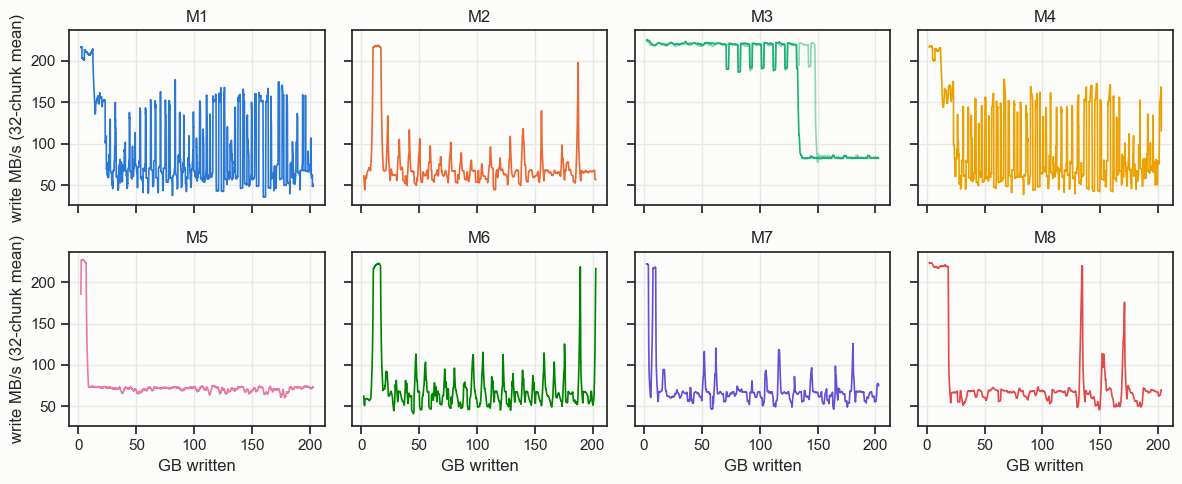

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharex=True, sharey=True)
for ax, s in zip(axes.flat, SCOPES):
    for (sc, run), w in W.items():
        if sc == s:
            speed = 32 * CHUNK_MB / w.write_s.rolling(32, min_periods=1).sum()   # bytes / time
            ax.plot(w.cum_gb, speed.where(w.index >= 31), color=COLORS[s], alpha=1 / run)
    ax.set_title(s)
for ax in axes[1]:
    ax.set_xlabel("GB written")
for ax in axes[:, 0]:
    ax.set_ylabel("write MB/s (32-chunk mean)")
fig.tight_layout()

In [7]:
def cache(w, drop=0.5, win=32):
    """GB written before the 32-chunk speed first falls below half the opening speed, and the speed after it."""
    s, gb = w.write_s.to_numpy(), w.cum_gb.to_numpy()
    roll = win * CHUNK_MB / pd.Series(s).rolling(win).sum().to_numpy()
    below = np.flatnonzero(roll < drop * 16 * CHUNK_MB / s[:16].sum())
    if not len(below):
        return np.nan, len(s) * CHUNK_MB / s.sum()
    cut = below[0] - win // 2
    return gb[cut], (len(s) - cut) * CHUNK_MB / s[cut:].sum()

cache_tab = pd.DataFrame([cache(w) for w in W.values()], index=runs.index,
                         columns=["cache_gb", "post_cache_mb_s"])
cache_tab.round(1)

cache_gb  post_cache_mb_s
scope run                           
M1    1        22.0             68.7
M2    1         1.7             67.5
M3    1       132.8             83.2
      2       147.5             83.2
M4    1        22.1             69.5
M5    1         7.4             70.9
M6    1         NaN             65.5
M7    1         3.2             65.8
M8    1        17.9             65.4

## How long single writes take

The distribution of the time each 64 MiB chunk took to reach the drive, on a log axis. A curve that rises
steeply in one place means a steady drive. A long tail to the right is stalls. One chunk holds about 4.3 s of
video at 15.7 MB/s, so chunks slower than that are moments the drive fell behind real time.

,median,p99,worst,over_real_time,over_10s
scope,,,,,
M1,0.42,12.23,12.86,137,68
M2,1.00,2.36,8.00,5,0
M3,0.31,0.85,3.98,0,0
M4,0.43,12.22,12.90,142,65
M5,0.94,1.24,1.44,0,0
M6,1.01,2.42,13.39,9,1
M7,1.00,2.05,5.35,5,0
M8,0.98,2.01,2.35,0,0


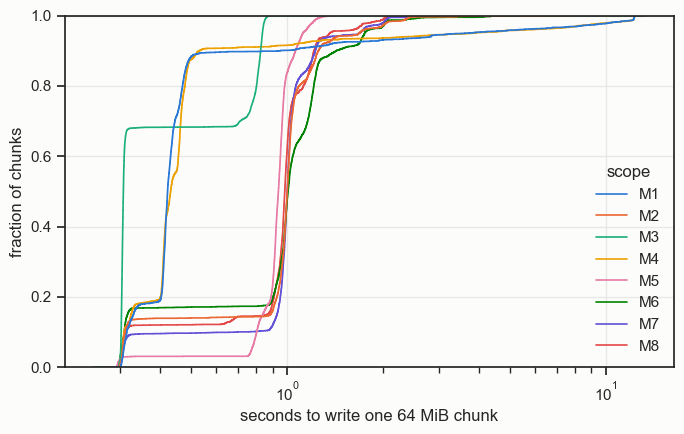

In [8]:
d = pd.concat([pd.DataFrame({"scope": k[0], "write_s": w.write_s}) for k, w in W.items()])
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.ecdfplot(d, x="write_s", hue="scope", palette=COLORS, log_scale=True, ax=ax)
ax.set_xlabel("seconds to write one 64 MiB chunk")
ax.set_ylabel("fraction of chunks")
fig.tight_layout()
d.groupby("scope").write_s.agg(median="median", p99=lambda x: x.quantile(0.99), worst="max",
                               over_real_time=lambda x: (x > RT_S).sum(),
                               over_10s=lambda x: (x > 10).sum()).round(2)

## Would a recording keep up?

A recording produces 15.7 MB every second. While one chunk takes *t* seconds to write, the recording adds
15.7 × *t* MB and the drive takes one chunk away. Count how much would be left waiting. Zero means the drive
kept up. Tall or long peaks are data a recording would have to hold in memory until the drive caught up.

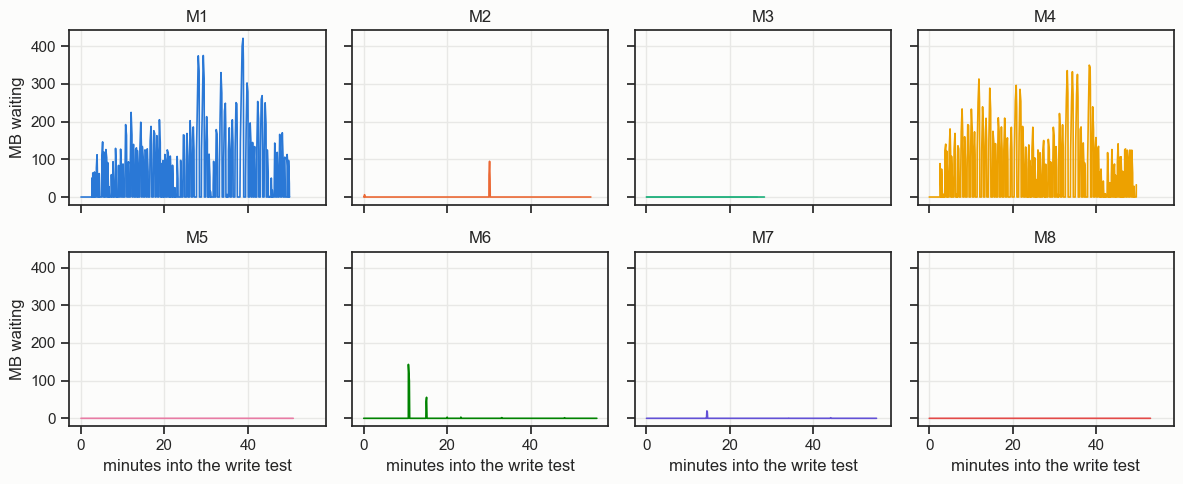

In [9]:
def queue(write_s, rate=REQ):
    q, out = 0.0, []
    for t in write_s:
        q = max(0.0, q + rate * t - CHUNK_MB)
        out.append(q)
    return np.array(out)

fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharex=True, sharey=True)
behind = {}
for ax, s in zip(axes.flat, SCOPES):
    for (sc, run), w in W.items():
        if sc == s:
            q = queue(w.write_s.to_numpy())
            behind[(sc, run)] = q.max()
            ax.plot(w.minutes, q, color=COLORS[s], alpha=1 / run)
    ax.set_title(s)
for ax in axes[1]:
    ax.set_xlabel("minutes into the write test")
for ax in axes[:, 0]:
    ax.set_ylabel("MB waiting")
fig.tight_layout()

## Read-back

Every chunk is read back from the drive, not from memory, and checked against its CRC. One point per file; the
box shows the median and interquartile range for each scope. The USB bridge, not the flash, usually sets the
ceiling here, so drives behind the same bridge should line up.

,files,chunks_bad
scope,,
M1,20,0.0
M2,20,0.0
M3,40,0.0
M4,20,0.0
M5,20,0.0
M6,20,0.0
M7,20,0.0
M8,20,0.0


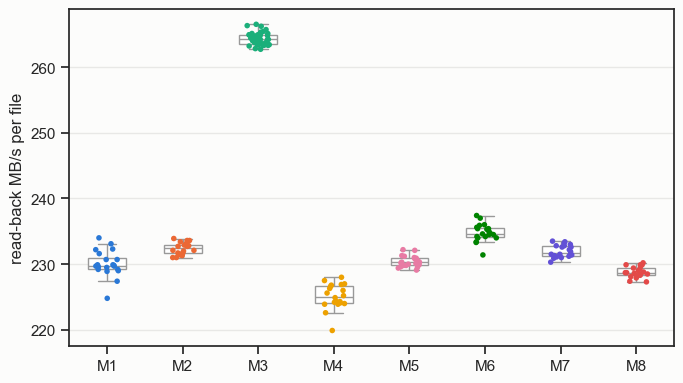

In [10]:
rb = (res.query("stream == 'verify' and disk == 'sda'")
      .assign(scope=lambda d: d.eid.map(runs.reset_index().set_index("eid").scope)))
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(rb, x="scope", y="read_mb_s", order=SCOPES, color="white", width=0.5,
            showfliers=False, ax=ax)
sns.stripplot(rb, x="scope", y="read_mb_s", order=SCOPES, hue="scope", palette=COLORS,
              size=4, jitter=0.15, legend=False, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("read-back MB/s per file")
fig.tight_layout()
rb.groupby("scope").agg(files=("read_mb_s", "size"), chunks_bad=("chunks_bad", "sum"))

## Results

In [11]:
def ident(k, r):
    sd, ssd = dev(k, "mmcblk0"), dev(k, "sda")
    smart = open(find(r.dir, "sda/smart_before.txt")).read()
    fw = re.search(r"Firmware Version:\s*(\S+)", smart)
    trim = J[k].get("fstrim", {}).get("sda", "")
    trim = trim.get("supported") if isinstance(trim, dict) else "trimmed" in trim
    b, a = ssd["smart_before"], ssd["smart_after"]
    f = ssd["workload"]["files"]
    return {"model": ssd["identity"].get("model"), "firmware": fw.group(1) if fw else None,
            "bridge": ssd["identity"].get("bridge"), "trim": trim,
            "slowest_file_mb_s": min(x["mean_mb_s"] for x in f),
            "worst_chunk_s": W[k].write_s.max(),
            "chunks_over_real_time": int((W[k].write_s > RT_S).sum()),
            "lifetime_tb_written": ssd.get("lifetime_written_tb"),
            "page_cache_room_mb": J[k].get("page_cache", {}).get("freerun_mb"),
            "read_mb_s": np.median([x["read_mb_s"] for x in f]),
            "crc_bad": sum(x["chunks_bad"] for x in f),
            "smart": b.get("health"),
            "smart_worse": any(a.get(c, 0) > b.get(c, 0) for c in
                               ("realloc", "pending", "media_errors", "crc_errors")),
            "kernel_errors": len(ssd.get("kernel_storage_errors", [])),
            "sd_write_mb_s": sd["workload"]["files"][0]["mean_mb_s"],
            "sd_read_mb_s": sd["workload"]["files"][0]["read_mb_s"]}

fleet = pd.DataFrame([ident(k, r) for k, r in runs.iterrows()], index=runs.index)
fleet = (runs[["eid"]].join(fleet).join(cache_tab)
         .assign(behind_mb_max=[behind[k] for k in runs.index]))

In [12]:
fail = ((fleet.crc_bad > 0) | (fleet.smart != "PASSED") | fleet.smart_worse
        | (fleet.kernel_errors > 0) | (fleet.post_cache_mb_s < 3 * REQ)
        | (fleet.behind_mb_max > fleet.page_cache_room_mb))   # a recording would block on write
warn = fleet.behind_mb_max > 2 * REQ                       # more than 2 s of video waiting
fleet["verdict"] = np.select([fail, warn], ["FAIL", "WARN"], "PASS")

os.makedirs(OUT, exist_ok=True)
fleet.to_csv(f"{OUT}/storage_health.csv")
for k, row in fleet.iterrows():                           # one copy next to each run's data
    with open(os.path.join(exps.get_analysis_dir(row.eid), "storage_health.yaml"), "w") as f:
        yaml.safe_dump({c: (v.item() if hasattr(v, "item") else v) for c, v in row.items()}, f)
fleet.round(2)

eid                    model  firmware     bridge   trim  \
scope run                                                                    
M1    1    c57e742f68          NTech MX600 SSD   V1027A0  174c:55aa  False   
M2    1    39224596ea          NTech MX600 SSD   Y0407A2  174c:55aa  False   
M3    1    f85983c6bf          Elements SE SSD  331030WD  1058:266e   True   
      2    e562c0767e          Elements SE SSD  331030WD  1058:266e   True   
M4    1    222d2f4dbb          NTech MX600 SSD   V1027A0  174c:55aa  False   
M5    1    2188f16747  Samsung SSD 870 QVO 1TB  SVQ02B6Q  174c:55aa  False   
M6    1    e7fb1406d0          NTech MX600 SSD   Y0407A2  174c:55aa  False   
M7    1    f618a334ff          NTech MX600 SSD   Y0407A2  174c:55aa  False   
M8    1    be10bdc68a          NTech MX600 SSD   Y0407A2  174c:55aa  False   

           slowest_file_mb_s  worst_chunk_s  chunks_over_real_time  \
scope run                                                            
M1    1                 56.0          12.86                    137   
M2    1                 54.0           8.00                      5   
M3    1                 71.5           1.01                      0   
      2                 71.2           3.98                      0   
M4    1                 53.1          12.90                    142   
M5    1                 58.1           1.44                      0   
M6    1                 52.1          13.39                      9   
M7    1                 53.5           5.35                      5   
M8    1                 53.7           2.35                      0   

           lifetime_tb_written  page_cache_room_mb  ...  crc_bad   smart  \
scope run                                           ...                    
M1    1                  20.20                1032  ...        0  PASSED   
M2    1                  13.82                1042  ...        0  PASSED   
M3    1                  10.65                1022  ...        0  PASSED   
      2                  10.85                1041  ...        0  PASSED   
M4    1                  16.99                1053  ...        0  PASSED   
M5    1                   8.47                1045  ...        0  PASSED   
M6    1                  10.09                1036  ...        0  PASSED   
M7    1                  11.89                1025  ...        0  PASSED   
M8    1                   9.31                1057  ...        0  PASSED   

          smart_worse  kernel_errors  sd_write_mb_s  sd_read_mb_s  cache_gb  \
scope run                                                                     
M1    1         False              0           14.8          42.0     22.01   
M2    1         False              0           14.7          40.6      1.68   
M3    1         False              0           10.4          40.7    132.81   
      2         False              0            9.5          40.6    147.50   
M4    1         False              0           15.4          40.5     22.08   
M5    1         False              0           17.0          40.7      7.45   
M6    1         False              0            9.6          42.0       NaN   
M7    1         False              0           12.4          40.8      3.15   
M8    1         False              0           14.4          40.6     17.92   

           post_cache_mb_s  behind_mb_max  verdict  
scope run                                           
M1    1              68.71         421.30     WARN  
M2    1              67.52          94.78     WARN  
M3    1              83.17           0.00     PASS  
      2              83.17           0.00     PASS  
M4    1              69.54         349.97     WARN  
M5    1              70.90           0.00     PASS  
M6    1              65.47         143.14     WARN  
M7    1              65.83          19.67     PASS  
M8    1              65.41           0.00     PASS  

[9 rows x 21 columns]

## Acceptance

Per scope, for the experiment SSD:

| Criterion | Level |
|---|---|
| Any chunk reads back wrong (CRC) | FAIL |
| SMART not PASSED, or reallocated, pending, media or link-CRC errors rose during the run | FAIL |
| A kernel storage error or reset on the drive during the run | FAIL |
| Speed after the cache runs out below 3 × 15.7 = 47 MB/s | FAIL |
| A 15.7 MB/s recording would have more waiting than the page cache holds before Linux throttles writers | FAIL |
| A 15.7 MB/s recording would have more than 2 s of video (31 MB) waiting | WARN |

WARN is informational: this test bypasses the page cache, but a real recording writes through it, so anything
below the page-cache room (`page_cache_room_mb`, read from the scope's `vm.dirty_*` settings) is absorbed
without the recording ever waiting.
TRIM and the SD card figures are reported but not judged: most USB bridges do not pass TRIM, and the SD card
holds the OS, not recordings.

## Persistent records

This calibration writes 0 records to the scope.